In [47]:
import networkx as nx
from torch_geometric.datasets import TUDataset
import networkx as nx
from magnipy.magnitude.distances import get_dist
from diversity_curves.process import (
    get_mag_graphs,
    get_weight_diffs,
    get_funs_diff,
    get_mag_areas,
    get_mag_funs_graphs,
)
import argparse
import os
import seaborn as sns
from diversity_curves.process import get_funs_df
from diversity_curves.utils import graph_processing_torch
import pandas as pd

In [26]:
dataset_name = "MCF-7"

results_dir = f"./results/{dataset_name}/"

if not os.path.exists(results_dir):
    os.makedirs(results_dir, exist_ok=True)

root = "./../datasets/TUDataset"
pyg_dataset = TUDataset(root=root, name=dataset_name)
pyg_dataset

MCF-7(27770)

In [27]:
n_nodes = [c.num_nodes for c in pyg_dataset]
min(n_nodes)

3

In [28]:
lables = [data.y.item() for data in pyg_dataset]

In [52]:
df_nnodes = pd.DataFrame([n_nodes, lables]).T
df_nnodes.columns = ["nodes", "class"]

<Axes: >

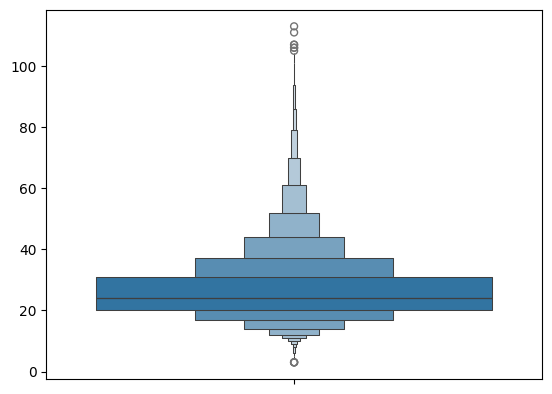

In [29]:
import seaborn as sns
sns.boxenplot(n_nodes)

In [30]:
import pandas as pd
df = pd.read_csv("/home/limbeckkat/Code/diversity_curves/mcf/results/MCF-7/mag_funs_shortest_path_distance.csv", index_col=0)

In [31]:
pd.Series(lables).value_counts()

0    25476
1     2294
dtype: int64

In [ ]:
pd.Series(lables).value_counts()/len(lables)

0    0.917393
1    0.082607
dtype: float64

In [32]:
bols=[r in df.index for r in range(len(lables))]

In [33]:
df

,1,5,10,15,20,25,30,35,40,45,50
graph,,,,,,,,,,,
0,1,3.305302,5.082692,6.804881,8.652040,10.705331,12.710213,14.659652,16.699471,18.766693,20.564799
1,1,3.368716,5.355294,7.045371,8.546040,10.152377,11.663282,13.512446,15.262791,17.110828,18.908457
2,1,2.792783,4.765570,6.679330,8.195229,9.813052,11.751736,13.667458,15.527955,17.544157,18.207630
3,1,2.792783,4.737618,6.539637,8.137934,9.947837,11.707338,13.540430,15.447531,17.548447,18.286685
4,1,2.755698,4.615189,6.635428,8.429164,10.020663,11.991728,13.884723,15.802649,17.121333,17.500458
...,...,...,...,...,...,...,...,...,...,...,...
27765,1,2.748404,4.339673,6.275977,7.936237,8.264786,8.574544,8.897158,9.297955,9.343101,9.422947
27766,1,2.773162,4.842820,6.411324,6.940318,7.166914,7.344836,7.528935,7.777832,7.895326,7.925387
27767,1,2.725359,4.746200,6.680602,8.660091,10.718052,12.793212,14.552049,15.036167,15.224305,15.638958


In [34]:
df["class"] = pd.Series(lables)[bols]

In [35]:
num_cols = ["1"]+[str(r) for r in range(5, 51, 5)]
df_long = (
    df
    .reset_index()
    .rename(columns={"index": "graph_index"})
    .melt(
        id_vars="class",
        value_vars=num_cols,
        var_name="n_nodes",
        value_name="value"
    )
)

df_long["n_nodes"] = df_long["n_nodes"].astype(int)
#df_long = df_long[df_long.n_nodes < 35]

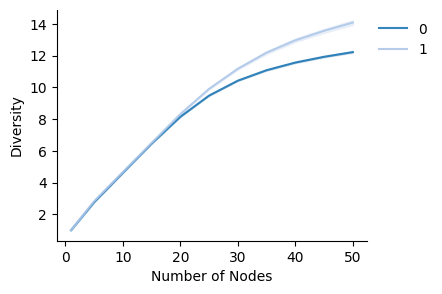

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

#df_long["class"] = df_long["class"]#.map(dict_rename)
plt.figure(figsize=(4,3))
sns.lineplot(data=df_long, x="n_nodes", y="value", hue="class", palette="tab20", alpha=0.9)
sns.despine()
plt.legend(bbox_to_anchor=(1, 1), frameon=False)
sns.despine()
plt.xlabel("Number of Nodes")
plt.ylabel("Diversity")
plt.grid(False)

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols] = df[num_cols].interpolate(method="linear", axis=0, limit_direction="both")

pca = PCA(n_components=2)
proj = pca.fit_transform(StandardScaler().fit_transform(X=df.drop(columns="class")))

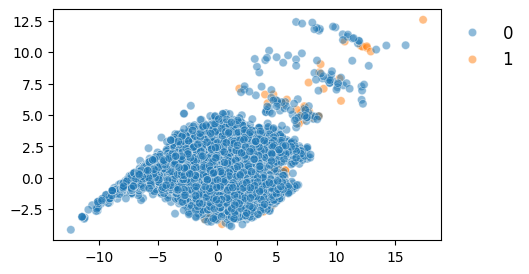

In [38]:
plt.figure(figsize=(5,3))
sns.scatterplot(x=proj[:, 0], y=proj[:, 1], hue=df["class"], palette="tab10", alpha=0.5)
plt.legend(bbox_to_anchor=(1, 1), frameon=False, fontsize=12)

<Axes: >

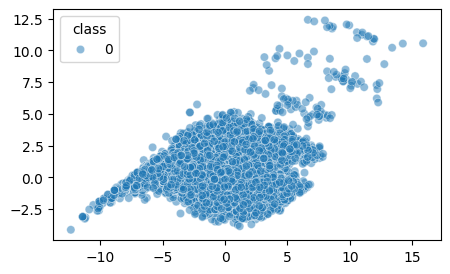

In [39]:
plt.figure(figsize=(5,3))
sns.scatterplot(x=proj[:, 0][df["class"]==0], y=proj[:, 1][df["class"]==0], hue=df["class"][df["class"]==0], palette="tab10", alpha=0.5)

<Axes: >

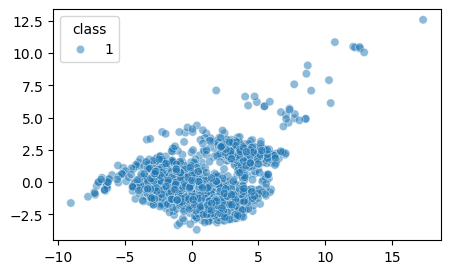

In [40]:
plt.figure(figsize=(5,3))
sns.scatterplot(x=proj[:, 0][df["class"]==1], y=proj[:, 1][df["class"]==1], hue=df["class"][df["class"]==1], palette="tab10", alpha=0.5)

In [41]:
from diversity_curves.stats import two_sample_test_matrix
test_results_df, test_results_stats_df = two_sample_test_matrix(df, class_col="class", drop_cols=["class"], n_permutations=1000, seed=42)

In [42]:
test_results_df

,1,0
1,1.000000,0.000999
0,0.000999,1.000000


In [ ]:
from diversity_curves.classifiers import *
X =df.drop(columns="class").values
y=df["class"].values
test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=y, precomputed=False, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=42, scale=False)

Fold 0: test accuracy = 0.9172, test balanced accuracy = 0.5286, test AUROC = 0.6491
Fold 1: test accuracy = 0.9150, test balanced accuracy = 0.5314, test AUROC = 0.6212
Fold 2: test accuracy = 0.9141, test balanced accuracy = 0.5200, test AUROC = 0.6424
Fold 3: test accuracy = 0.9146, test balanced accuracy = 0.5293, test AUROC = 0.6470
Fold 4: test accuracy = 0.9182, test balanced accuracy = 0.5292, test AUROC = 0.6558

Mean test accuracy: 0.9158
Std test accuracy:  0.0016
Mean balanced test accuracy: 0.5277
Std balanced test accuracy:  0.0040
Mean test AUROC: 0.6431
Std test AUROC:  0.0118


In [46]:
from diversity_curves.classifiers import *
X =df.drop(columns="class").values
y=df["class"].values
test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=y, precomputed=False, outer_k=10, holdout_test_size=0.1, stratify=True, tune=True, seed=42, scale=False)

Fold 0: test accuracy = 0.9179, test balanced accuracy = 0.5340, test AUROC = 0.6666
Fold 1: test accuracy = 0.9132, test balanced accuracy = 0.5295, test AUROC = 0.6507
Fold 2: test accuracy = 0.9125, test balanced accuracy = 0.5212, test AUROC = 0.6143
Fold 3: test accuracy = 0.9175, test balanced accuracy = 0.5338, test AUROC = 0.6576
Fold 4: test accuracy = 0.9157, test balanced accuracy = 0.5249, test AUROC = 0.6193
Fold 5: test accuracy = 0.9168, test balanced accuracy = 0.5413, test AUROC = 0.6496
Fold 6: test accuracy = 0.9135, test balanced accuracy = 0.5217, test AUROC = 0.6584
Fold 7: test accuracy = 0.9153, test balanced accuracy = 0.5266, test AUROC = 0.6508
Fold 8: test accuracy = 0.9164, test balanced accuracy = 0.5292, test AUROC = 0.6725
Fold 9: test accuracy = 0.9171, test balanced accuracy = 0.5276, test AUROC = 0.6611

Mean test accuracy: 0.9156
Std test accuracy:  0.0018
Mean balanced test accuracy: 0.5290
Std balanced test accuracy:  0.0058
Mean test AUROC: 0.6501

In [53]:
from diversity_curves.classifiers import *
X =df_nnodes.drop(columns="class").values
y=df["class"].values
test_accs, test_aurocs, test_accs_balanced, conf_matrices = knn_classifier_cv(X=X, y=y, precomputed=False, outer_k=10, holdout_test_size=0.1, stratify=True, tune=True, seed=42, scale=False)

Fold 0: test accuracy = 0.9053, test balanced accuracy = 0.5153, test AUROC = 0.5692
Fold 1: test accuracy = 0.9186, test balanced accuracy = 0.5186, test AUROC = 0.5921
Fold 2: test accuracy = 0.9175, test balanced accuracy = 0.5160, test AUROC = 0.6023
Fold 3: test accuracy = 0.9179, test balanced accuracy = 0.5103, test AUROC = 0.5572
Fold 4: test accuracy = 0.9153, test balanced accuracy = 0.5048, test AUROC = 0.5916
Fold 5: test accuracy = 0.9107, test balanced accuracy = 0.5062, test AUROC = 0.5416
Fold 6: test accuracy = 0.9128, test balanced accuracy = 0.5114, test AUROC = 0.5410
Fold 7: test accuracy = 0.9171, test balanced accuracy = 0.5058, test AUROC = 0.5713
Fold 8: test accuracy = 0.9171, test balanced accuracy = 0.5097, test AUROC = 0.5965
Fold 9: test accuracy = 0.9107, test balanced accuracy = 0.5062, test AUROC = 0.5676

Mean test accuracy: 0.9143
Std test accuracy:  0.0041
Mean balanced test accuracy: 0.5104
Std balanced test accuracy:  0.0046
Mean test AUROC: 0.5730

In [44]:
#test_accs, test_aurocs, test_accs_balanced, conf_matrices = svm_classifier_cv(X=X, y=y, precomputed=False, outer_k=5, holdout_test_size=0.2, stratify=True, tune=True, seed=42, scale=True)